In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from study_config import *

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

d = pd.read_csv(PROC / "retail_clean_flagged.csv", parse_dates=["date"])
d["ym"] = d["date"].dt.to_period("M")
ids = ["market_id", "commodity_id"]
ALL = pd.period_range("2016-01", "2026-06", freq="M")

design = pd.DataFrame([{"window": w, "train": f"{a} to {b}", "train_months": len(pd.period_range(a, b, freq="M")),
                        "test": f"{c} to {e}", "test_months": len(pd.period_range(c, e, freq="M"))}
                       for w, (a, b, c, e) in WINDOWS.items()])
display(design)
design.to_csv(TAB / "11_window_design.csv", index=False)

,window,train,train_months,test,test_months
0,Pre-pandemic,2016-01 to 2018-05,29,2018-06 to 2019-05,12
1,Pandemic,2020-05 to 2022-05,25,2022-06 to 2023-05,12
2,Post-pandemic,2020-05 to 2025-06,62,2025-07 to 2026-06,12


In [2]:
pres = (d.assign(v=1).pivot_table(index=ids, columns="ym", values="v", aggfunc="max")
          .reindex(columns=ALL).notna())
meta = d.groupby(ids).agg(category=("category", "first"), commodity=("commodity", "first"),
                          market=("market", "first"), admin1=("admin1", "first")).reset_index()

def longest_gap(row):
    best = cur = 0
    for x in row:
        cur = 0 if x else cur + 1
        best = max(best, cur)
    return best

parts = []
for w, (a, b, c, e) in WINDOWS.items():
    tr, te = pd.period_range(a, b, freq="M"), pd.period_range(c, e, freq="M")
    ptr, pte = pres[tr], pres[te]
    parts.append(pd.DataFrame({"window": w, "train_len": len(tr), "test_len": len(te),
                               "train_obs": ptr.sum(axis=1), "test_obs": pte.sum(axis=1),
                               "max_gap": [longest_gap(x) for x in ptr.to_numpy()]},
                              index=pres.index).reset_index())
W = pd.concat(parts, ignore_index=True)
W["train_cov"] = (W["train_obs"] / W["train_len"]).round(3)
W["fail_cov"] = W["train_cov"] < ELIG["min_train_cov"]
W["fail_gap"] = W["max_gap"] > ELIG["max_gap"]
W["fail_test"] = W["test_obs"] < ELIG["min_test_obs"]
W["eligible"] = ~(W["fail_cov"] | W["fail_gap"] | W["fail_test"])
W = W.merge(meta, on=ids)
W.to_csv(TAB / "11_eligibility_by_series_window.csv", index=False)

print("Series with training data, rule failures (reasons overlap), and eligible series:")
display(W[W["train_obs"] > 0].groupby("window").agg(series_with_data=("train_obs", "size"),
        fail_coverage=("fail_cov", "sum"), fail_gap=("fail_gap", "sum"),
        fail_test=("fail_test", "sum"), eligible=("eligible", "sum")))

def n_elig(cov, gap, test):
    return W[(W["train_cov"] >= cov) & (W["max_gap"] <= gap) & (W["test_obs"] >= test)].groupby("window").size().to_dict()
print("Sensitivity (eligible series per window):")
print("  strict (90%, gap<=2, test>=10):", n_elig(0.9, 2, 10))
print("  main   (80%, gap<=3, test>=9) :", n_elig(0.8, 3, 9))
print("  loose  (70%, gap<=4, test>=6) :", n_elig(0.7, 4, 6))

Series with training data, rule failures (reasons overlap), and eligible series:


,series_with_data,fail_coverage,fail_gap,fail_test,eligible
window,,,,,
Pandemic,4361,2114,2356,1843,2005
Post-pandemic,4369,1959,2364,1746,2005
Pre-pandemic,252,91,97,17,153


Sensitivity (eligible series per window):
  strict (90%, gap<=2, test>=10): {'Pandemic': 1973, 'Post-pandemic': 1995, 'Pre-pandemic': 148}
  main   (80%, gap<=3, test>=9) : {'Pandemic': 2005, 'Post-pandemic': 2005, 'Pre-pandemic': 153}
  loose  (70%, gap<=4, test>=6) : {'Pandemic': 2016, 'Post-pandemic': 2016, 'Pre-pandemic': 161}


In [3]:
E = W[W["eligible"]].copy()
display(E.groupby("window").agg(series=("eligible", "size"), markets=("market_id", "nunique"),
        commodities=("commodity_id", "nunique"), regions=("admin1", "nunique"), categories=("category", "nunique")))
print("Eligible series by category:"); display(E.groupby(["category", "window"]).size().unstack("window").fillna(0).astype(int))
print("Eligible series by region:");   display(E.groupby(["admin1", "window"]).size().unstack("window").fillna(0).astype(int))
display(E.groupby("window").agg(train_obs_min=("train_obs", "min"), train_obs_median=("train_obs", "median"),
                                test_obs_min=("test_obs", "min"), test_obs_median=("test_obs", "median")))

sets = {w: set(map(tuple, E[E["window"] == w][ids].to_numpy())) for w in WINDOWS}
print("Series eligible in both windows:",
      {"Pandemic & Post": len(sets["Pandemic"] & sets["Post-pandemic"]),
       "Pre & Pandemic": len(sets["Pre-pandemic"] & sets["Pandemic"]),
       "Pre & Post": len(sets["Pre-pandemic"] & sets["Post-pandemic"])})
c5 = E.groupby(["window", "commodity"]).size().unstack(0).fillna(0)
print("Commodities with >= 5 eligible series:", (c5 >= 5).sum().to_dict(), "| with >= 1:", (c5 > 0).sum().to_dict())

,series,markets,commodities,regions,categories
window,,,,,
Pandemic,2005,78,56,17,4
Post-pandemic,2005,78,56,17,4
Pre-pandemic,153,17,15,17,3


Eligible series by category:


window,Pandemic,Post-pandemic,Pre-pandemic
category,,,
cereals and tubers,226,226,44
"meat, fish and eggs",748,748,61
pulses and nuts,86,86,0
vegetables and fruits,945,945,48


Eligible series by region:


window,Pandemic,Post-pandemic,Pre-pandemic
admin1,,,
Autonomous region in Muslim Mindanao,70,70,9
Cordillera Administrative region,155,155,10
National Capital region,16,16,3
Region I,105,105,7
Region II,105,105,7
Region III,202,202,11
Region IV-A,127,127,11
Region IV-B,134,134,11
Region IX,86,86,9


,train_obs_min,train_obs_median,test_obs_min,test_obs_median
window,,,,
Pandemic,20,25.0,12,12.0
Post-pandemic,57,62.0,11,12.0
Pre-pandemic,25,29.0,9,12.0


Series eligible in both windows: {'Pandemic & Post': 2005, 'Pre & Pandemic': 0, 'Pre & Post': 0}
Commodities with >= 5 eligible series: {'Pandemic': 49, 'Post-pandemic': 49, 'Pre-pandemic': 13} | with >= 1: {'Pandemic': 56, 'Post-pandemic': 56, 'Pre-pandemic': 15}


In [4]:
lp = (d.pivot_table(index=ids, columns="ym", values="log_price", aggfunc="first").reindex(columns=ALL))
arr = lp.to_numpy()
row_of = {k: i for i, k in enumerate(lp.index)}
pos = {m: i for i, m in enumerate(ALL)}

recs = []
for r in E.itertuples(index=False):
    a, b, c, e = WINDOWS[r.window]
    i = row_of[(r.market_id, r.commodity_id)]
    tr = np.arange(pos[pd.Period(a, "M")], pos[pd.Period(b, "M")] + 1)
    x = arr[i, tr]
    valid = ~np.isnan(x)
    f, l = np.where(valid)[0][[0, -1]]                  # trim to first and last observed month
    idx = np.arange(f, l + 1)
    v = valid[f:l + 1]
    y = np.interp(idx, idx[v], x[idx][v])               # linear interpolation of log price across small gaps
    for j, (yy, ff) in enumerate(zip(y, ~v)):
        recs.append((r.window, r.market_id, r.commodity_id, str(ALL[tr[f + j]]), "train", float(yy), bool(ff), 0))
    last_ord = ALL[tr[l]].ordinal
    for m in pd.period_range(c, e, freq="M"):
        val = arr[i, pos[m]]
        if not np.isnan(val):                           # test months are scored only where actually observed
            recs.append((r.window, r.market_id, r.commodity_id, str(m), "test", float(val), False, m.ordinal - last_ord))

panel = pd.DataFrame(recs, columns=["window", "market_id", "commodity_id", "ym", "role", "log_price", "filled", "h"])
panel["price"] = np.exp(panel["log_price"])
panel = panel.merge(meta, on=ids)
panel.to_csv(PROC / "forecast_panel.csv", index=False)

print("Panel rows:", len(panel))
display(panel.groupby(["window", "role"]).size().unstack())
tr_ = panel[panel["role"] == "train"]
print("Filled training months:", int(tr_["filled"].sum()), "| series-windows with >= 1:",
      tr_[tr_["filled"]].groupby(["window", "market_id", "commodity_id"]).ngroups)
print("Training length per series:")
display(tr_.groupby("window").apply(lambda g: g.groupby(ids).size().agg(["min", "median", "max"])))
te_ = panel[panel["role"] == "test"]
print("Test horizons present:", te_["h"].min(), "to", te_["h"].max(), "| test observations:", len(te_))

Panel rows: 228522


role,test,train
window,,
Pandemic,24060,50013
Post-pandemic,24053,124198
Pre-pandemic,1763,4435


Filled training months: 736 | series-windows with >= 1: 519
Training length per series:


,min,median,max
window,,,
Pandemic,22.0,25.0,25.0
Post-pandemic,59.0,62.0,62.0
Pre-pandemic,28.0,29.0,29.0


Test horizons present: 1 to 12 | test observations: 49876


Series-windows to fit: 4163
  candidate grid of  6 models -> 24,978 fits
  candidate grid of 12 models -> 49,956 fits
  candidate grid of 27 models -> 112,401 fits


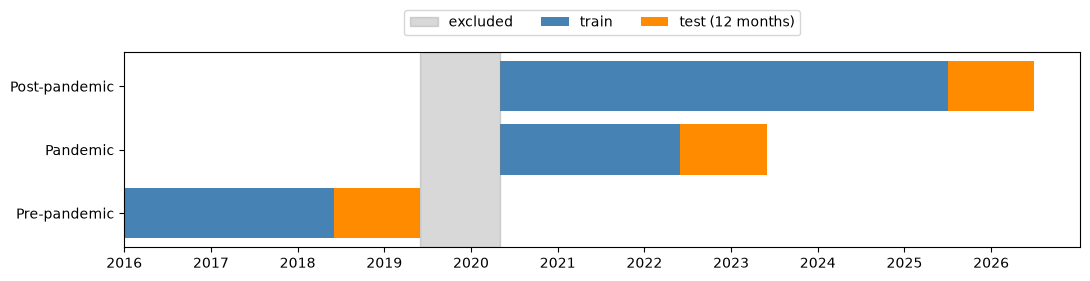

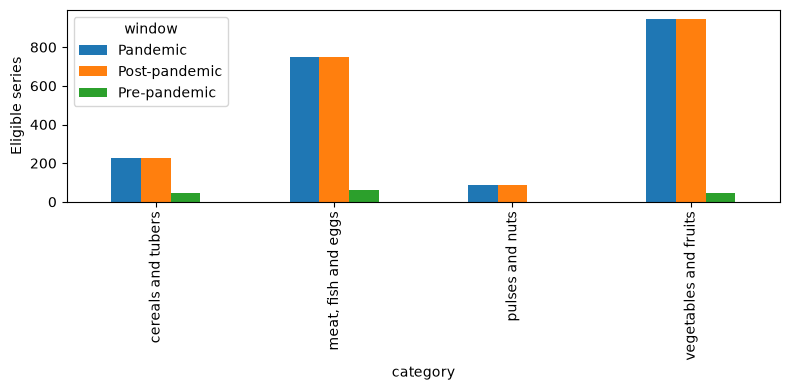

In [5]:
n_sw = len(E)
print(f"Series-windows to fit: {n_sw}")
for grid_size in (6, 12, 27):
    print(f"  candidate grid of {grid_size:>2} models -> {n_sw * grid_size:,} fits")

fig, ax = plt.subplots(figsize=(11, 3))
for i, (w, (a, b, c, e)) in enumerate(WINDOWS.items()):
    ax.barh(i, (pd.Period(b, "M") - pd.Period(a, "M")).n + 1, left=pd.Period(a, "M").ordinal,
            color="steelblue", label="train" if i == 0 else None)
    ax.barh(i, 12, left=pd.Period(c, "M").ordinal, color="darkorange", label="test (12 months)" if i == 0 else None)
ax.axvspan(pd.Period("2019-06", "M").ordinal, pd.Period("2020-04", "M").ordinal + 1, color="grey", alpha=0.3, label="excluded")
ax.set_yticks(range(3)); ax.set_yticklabels(list(WINDOWS))
ax.set_xticks([pd.Period(f"{y}-01", "M").ordinal for y in range(2016, 2027)]); ax.set_xticklabels(range(2016, 2027))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25))
plt.tight_layout(); plt.savefig(FIG / "11_window_design.png", dpi=150); plt.show()

E.groupby(["category", "window"]).size().unstack("window").fillna(0).plot(kind="bar", figsize=(8, 4))
plt.ylabel("Eligible series"); plt.tight_layout()
plt.savefig(FIG / "11_eligible_by_category.png", dpi=150); plt.show()